# 03 — Full signing cost and the size-vs-work frontier (E4, RQ3, H2, H3)

**E4, full sign-path cost** = base signing compressions (tree building, WOTS/FORS/PORS leaves; from the
cost model, `ref/costs.py`) + grinding (measured per-signature distribution from notebook 02, priced at
the counted compressions per attempt). The model's own total charges FORS+C / PORS+FP attempts
4 compressions; the difference to the re-priced total is shown.

**Frontier:** for each signature limit (2²⁰ / 2³⁰ / 2⁴⁰), the points that no other point beats on both
bytes and p99 signing work. Time budgets per signer class turn it into "smallest signature you can afford".

In [1]:
import sys; sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import common as C
from runner.configs import COMPRESSIONS
OUT = C.out_dir('03_pareto')
sl = C.shortlist()
lad = C.ladder()

## E4 — full signing cost per point and grind layout

In [2]:
rows = []
for pid, fcid, kind in C.point_layouts():
    pt = sl.loc[pid]
    base = C.base_compressions(pt)
    w, f = C.signature_grind_samples(pid, fcid)
    grind = w + f * (COMPRESSIONS[kind] if kind else 0)
    total = base + grind
    rows.append({'param_id': pid, 'layout': kind or '-', 'profile': pt.profile, 'variant': pt.variant,
                 'sig_limit': int(pt.sig_limit_log2), 'sig_bytes': int(pt.sig_bytes) + (4 if kind == 'ctr' else 0),
                 'base_comp': base, 'grind_mean': grind.mean(), 'grind_p99': np.quantile(grind, 0.99),
                 'total_mean': total.mean(), 'total_p99': np.quantile(total, 0.99), 'total_p999': np.quantile(total, 0.999),
                 'model_total_mean': float(pt.sign_compressions_cached),
                 'grind_share_mean': grind.mean() / total.mean(),
                 'verify_comp': int(pt.verify_compressions_cached)})
e4 = pd.DataFrame(rows).set_index(['param_id', 'layout'])
e4['measured_vs_model'] = e4.total_mean / e4.model_total_mean
e4.to_csv(OUT / 'e4_sign_cost.csv'); C.to_markdown(e4.round(4), OUT / 'e4_sign_cost.md')
print("ctr-grind adds a 4-byte counter to the signature (original SPHINCS+C layout); R-grind does not.")
print(f"grind share of mean signing work: {e4.grind_share_mean.min():.3f} .. {e4.grind_share_mean.max():.3f}")
print(f"re-priced / model total: {e4.measured_vs_model.min():.4f} .. {e4.measured_vs_model.max():.4f}")
e4[['profile', 'sig_bytes', 'base_comp', 'grind_mean', 'grind_share_mean', 'total_p99', 'measured_vs_model', 'verify_comp']]

ctr-grind adds a 4-byte counter to the signature (original SPHINCS+C layout); R-grind does not.
grind share of mean signing work: 0.000 .. 0.176
re-priced / model total: 0.9889 .. 1.0773


profile  \
param_id                                layout                        
L20-WC-h20d2-k10a15-w256S2040z0         -           blockstream_ref   
L20-WC-h24d2-k8a16-w16S240z0            -           blockstream_ref   
L20-WC-h24d2-k8a16-w256S2040z0          -           blockstream_ref   
L20-WCFC-h20d2-k10a15-w256S2040z0       R           blockstream_ref   
                                        ctr         blockstream_ref   
L20-WCFC-h24d2-k8a16-w16S240z0          R           blockstream_ref   
                                        ctr         blockstream_ref   
L20-WCPFP-h20d2-k10a15-w256S2040z0-m114 pors        blockstream_ref   
L20-WCPFP-h24d2-k7a18-w256S1912z1-m94   pors    gpu_signer_moderate   
L20-WCPFP-h24d2-k8a16-w16S240z0-m97     pors        blockstream_ref   
L20-WCPFP-h27d3-k10a12-w256S2040z0-m93  pors         hw_wallet_safe   
L20-WCPFP-h32d2-k11a10-w256S1912z1-m68  pors         gpu_signer_max   
L30-WC-h32d4-k10a14-w256S2040z0         -           blockstream_ref   
L30-WC-h32d4-k10a14-w256S2840z0         -           blockstream_ref   
L30-WC-h33d3-k9a15-w16S240z0            -           blockstream_ref   
L30-WC-h33d3-k9a15-w16S304z0            -           blockstream_ref   
L30-WC-h33d3-k9a15-w256S2040z0          -           blockstream_ref   
L30-WC-h36d3-k9a14-w16S240z0            -           blockstream_ref   
L30-WCFC-h32d2-k7a19-w256S1912z1        R             fors_c_stress   
                                        ctr           fors_c_stress   
L30-WCFC-h32d4-k10a14-w256S2040z0       R           blockstream_ref   
                                        ctr         blockstream_ref   
L30-WCFC-h33d3-k9a15-w16S240z0          R           blockstream_ref   
                                        ctr         blockstream_ref   
L30-WCFC-h33d3-k9a15-w256S2040z0        R           blockstream_ref   
                                        ctr         blockstream_ref   
L30-WCFC-h36d3-k9a14-w16S240z0          R           blockstream_ref   
                                        ctr         blockstream_ref   
L30-WCPFP-h32d2-k7a19-w256S1912z1-m96   pors         gpu_signer_max   
L30-WCPFP-h32d2-k7a19-w256S2512z1-m96   pors          wots_c_stress   
L30-WCPFP-h32d4-k10a14-w256S2040z0-m106 pors        blockstream_ref   
L30-WCPFP-h32d4-k9a15-w256S2040z0-m109  pors         hw_wallet_safe   
L30-WCPFP-h33d3-k8a16-w256S1912z1-m94   pors    gpu_signer_moderate   
L30-WCPFP-h33d3-k9a15-w16S240z0-m103    pors        blockstream_ref   
L30-WCPFP-h36d3-k9a14-w16S240z0-m93     pors        blockstream_ref   
L40-WC-h40d5-k11a14-w256S2040z0         -           blockstream_ref   
L40-WC-h40d5-k11a14-w256S2840z0         -           blockstream_ref   
L40-WC-h44d4-k8a16-w16S240z0            -           blockstream_ref   
L40-WC-h44d4-k8a16-w16S304z0            -           blockstream_ref   
L40-WC-h44d4-k8a16-w256S2040z0          -           blockstream_ref   
L40-WCFC-h40d5-k11a14-w256S2040z0       R           blockstream_ref   
                                        ctr         blockstream_ref   
L40-WCFC-h44d4-k8a16-w16S240z0          R           blockstream_ref   
                                        ctr         blockstream_ref   
L40-WCPFP-h40d5-k11a14-w256S2040z0-m118 pors        blockstream_ref   
L40-WCPFP-h44d4-k8a16-w16S240z0-m97     pors        blockstream_ref   
L40-WCPFP-h48d3-k9a13-w256S1912z1-m77   pors         gpu_signer_max   
L40-WCPFP-h48d4-k9a13-w256S1912z1-m82   pors    gpu_signer_moderate   
L40-WCPFP-h48d6-k9a13-w256S2440z0-m91   pors         hw_wallet_safe   

                                                sig_bytes    base_comp  \
param_id                                layout                           
L20-WC-h20d2-k10a15-w256S2040z0         -            3416    9383931.0   
L20-WC-h24d2-k8a16-w16S240z0            -            3608    5849085.0   
L20-WC-h24d2-k8a16-w256S2040z0          -            3096   35176445.0   
L20-WCFC-h20d2-k10a15-w256S2040z0       R            3160    9285624

Two readings matter for the paper:
- for every point **grinding is at most ≈18 % of mean signing work**; tree building dominates. The p99 tail of
  grinding therefore moves the p99 of signing only slightly, and the re-pricing at the true per-attempt cost
  (6 / 3 / 7 instead of 4 compressions) changes the model's totals by −1 % … +8 %.
- for the `gpu_signer_*` points the grind share rises, but the base cost (≈5·10⁸ compressions, a h/d ≥ 16
  hypertree layer) is still the larger part. These points are expensive because of the trees, not only the grinding.

## Frontier plot

param_id layout              profile  \
20 11   L20-WCPFP-h32d2-k11a10-w256S1912z1-m68   pors       gpu_signer_max   
   8     L20-WCPFP-h24d2-k7a18-w256S1912z1-m94   pors  gpu_signer_moderate   
   7   L20-WCPFP-h20d2-k10a15-w256S2040z0-m114   pors      blockstream_ref   
   10   L20-WCPFP-h27d3-k10a12-w256S2040z0-m93   pors       hw_wallet_safe   
   1              L20-WC-h24d2-k8a16-w16S240z0      -      blockstream_ref   
30 28    L30-WCPFP-h32d2-k7a19-w256S1912z1-m96   pors       gpu_signer_max   
   32    L30-WCPFP-h33d3-k8a16-w256S1912z1-m94   pors  gpu_signer_moderate   
   24         L30-WCFC-h33d3-k9a15-w256S2040z0      R      blockstream_ref   
   25         L30-WCFC-h33d3-k9a15-w256S2040z0    ctr      blockstream_ref   
   30  L30-WCPFP-h32d4-k10a14-w256S2040z0-m106   pors      blockstream_ref   
   31   L30-WCPFP-h32d4-k9a15-w256S2040z0-m109   pors       hw_wallet_safe   
   20        L30-WCFC-h32d4-k10a14-w256S2040z0      R      blockstream_ref   
   21        L30-WCFC-h32d4-k10a14-w256S2040z0    ctr      blockstream_ref   
   12          L30-WC-h32d4-k10a14-w256S2040z0      -      blockstream_ref   
   23           L30-WCFC-h33d3-k9a15-w16S240z0    ctr      blockstream_ref   
   14             L30-WC-h33d3-k9a15-w16S240z0      -      blockstream_ref   
40 46    L40-WCPFP-h48d3-k9a13-w256S1912z1-m77   pors       gpu_signer_max   
   47    L40-WCPFP-h48d4-k9a13-w256S1912z1-m82   pors  gpu_signer_moderate   
   39           L40-WC-h44d4-k8a16-w256S2040z0      -      blockstream_ref   
   48    L40-WCPFP-h48d6-k9a13-w256S2440z0-m91   pors       hw_wallet_safe   
   40        L40-WCFC-h40d5-k11a14-w256S2040z0      R      blockstream_ref   
   41        L40-WCFC-h40d5-k11a14-w256S2040z0    ctr      blockstream_ref   
   35          L40-WC-h40d5-k11a14-w256S2040z0      -      blockstream_ref   

       sig_bytes     total_p99  
20 11       2280  8.781755e+08  
   8        2504  5.771223e+07  
   7        2840  1.798477e+07  
   10       2876  6.521001e+06  
   1        3608  5.849516e+06  
30 28       2664  9.034018e+08  
   32       2908  4.803526e+07  
   24       3372  2.688951e+07  
   25       3376  2.644485e+07  
   30       3424  7.871447e+06  
   31       3456  5.201139e+06  
   20       3728  5.101935e+06  
   21       3732  4.869530e+06  
   12       3968  4.699481e+06  
   23       4144  4.446937e+06  
   14       4396  4.092447e+06  
40 46       2892  1.156355e+09  
   47       3216  8.303412e+07  
   39       3936  3.518396e+07  
   48       3944  6.655916e+06  
   40       4356  6.189268e+06  
   41       4360  5.972782e+06  
   35       4596  5.799863e+06

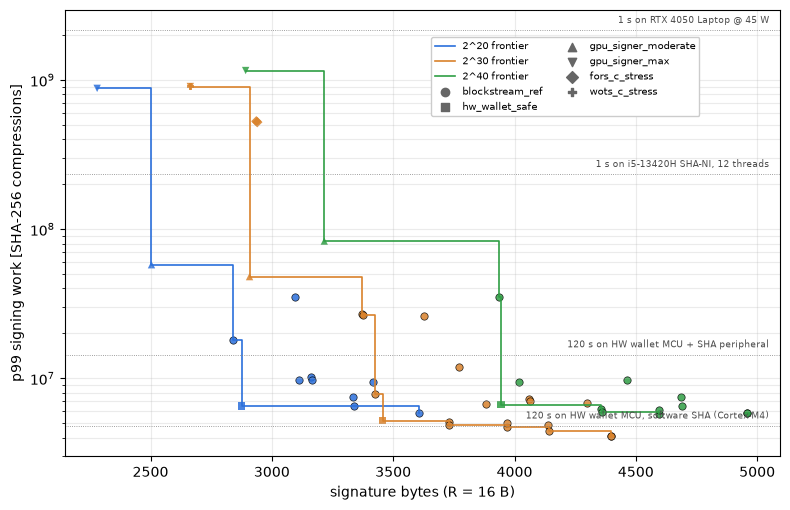

In [3]:
budgets = [  # (class_id, seconds) reference lines: what a p99 signature may cost
    ('class0a', 120), ('class0b', 120), ('class2', 1), ('class3', 1)]
cols = {20: '#2a6fdb', 30: '#d9822b', 40: '#2f9e44'}
mk = {'blockstream_ref': 'o', 'hw_wallet_safe': 's', 'gpu_signer_moderate': '^', 'gpu_signer_max': 'v',
      'fors_c_stress': 'D', 'wots_c_stress': 'P'}
fig, ax = plt.subplots(figsize=(8, 5.2))
front = {}
for L, g in e4.reset_index().groupby('sig_limit'):
    for prof, gg in g.groupby('profile'):
        ax.scatter(gg.sig_bytes, gg.total_p99, s=28, marker=mk[prof], color=cols[L],
                   edgecolor='k' if prof == 'blockstream_ref' else 'none', lw=0.5, alpha=0.85)
    g = g.sort_values(['sig_bytes', 'total_p99'])
    pf = g[g.total_p99 < g.total_p99.cummin().shift(fill_value=np.inf)]
    front[L] = pf
    ax.step(pf.sig_bytes, pf.total_p99, where='post', color=cols[L], lw=1.2, label=f'2^{L} frontier')
for cid, sec in budgets:
    y = lad.loc[cid, 'comp_per_s'] * sec
    ax.axhline(y, color='0.5', lw=0.6, ls=':')
    ax.text(5050, y * 1.12, f"{sec:g} s on {lad.loc[cid, 'label']}", fontsize=6.5, ha='right', color='0.3')
for prof, m in mk.items(): ax.scatter([], [], marker=m, color='0.4', label=prof)
ax.set_yscale('log'); ax.set_xlabel('signature bytes (R = 16 B)'); ax.set_ylabel('p99 signing work [SHA-256 compressions]')
ax.legend(fontsize=7, ncol=2, loc='upper center', bbox_to_anchor=(0.70, 0.95), framealpha=1); ax.grid(alpha=0.25, which='both')
fig.tight_layout(); fig.savefig(OUT / 'pareto_p99.png', dpi=160); fig.savefig(OUT / 'pareto_p99.svg')
pd.concat(front)[['param_id', 'layout', 'profile', 'sig_bytes', 'total_p99']]

## Smallest signature per time budget (answers OQ-2: "it would depend on their relative performance")

For each signer class and p99 budget, the smallest shortlisted signature whose p99 full signing time fits.


In [4]:
BUDGETS = [1, 10, 120, 600]
rows = []
for L in (20, 30, 40):
    g = e4.reset_index()
    g = g[g.sig_limit == L]
    for cid, r in lad.iterrows():
        for b in BUDGETS:
            ok = g[g.total_p99 / r.comp_per_s <= b]
            best = ok.loc[ok.sig_bytes.idxmin()] if len(ok) else None
            rows.append({'sig_limit': f'2^{L}', 'class': r.label, 'rate_kind': r.kind, 'p99_budget_s': b,
                         'smallest_sig_bytes': int(best.sig_bytes) if best is not None else None,
                         'param_id': best.param_id if best is not None else 'none fits',
                         'layout': best.layout if best is not None else ''})
bud = pd.DataFrame(rows)
C.to_markdown(bud, OUT / 'smallest_per_budget.md')
bud.pivot_table(index=['sig_limit', 'class'], columns='p99_budget_s', values='smallest_sig_bytes', aggfunc='first', sort=False)

p99_budget_s                                          1       10      120  \
sig_limit class                                                             
2^20      HW wallet MCU, software SHA (Cortex-M4)     NaN     NaN     NaN   
          HW wallet MCU + SHA peripheral              NaN     NaN  2876.0   
          Raspberry Pi 5 (ARMv8 SHA2)              2504.0  2504.0  2280.0   
          i5-13420H SHA-NI, 12 threads             2504.0  2280.0  2280.0   
          RTX 4050 Laptop @ 45 W                   2280.0  2280.0  2280.0   
          8x RTX 4090 server                       2280.0  2280.0  2280.0   
2^30      HW wallet MCU, software SHA (Cortex-M4)     NaN     NaN  3968.0   
          HW wallet MCU + SHA peripheral              NaN     NaN  3424.0   
          Raspberry Pi 5 (ARMv8 SHA2)              2908.0  2908.0  2664.0   
          i5-13420H SHA-NI, 12 threads             2908.0  2664.0  2664.0   
          RTX 4050 Laptop @ 45 W                   2664.0  2664.0  2664.0   
          8x RTX 4090 server                       2664.0  2664.0  2664.0   
2^40      HW wallet MCU, software SHA (Cortex-M4)     NaN     NaN     NaN   
          HW wallet MCU + SHA peripheral              NaN     NaN  3944.0   
          Raspberry Pi 5 (ARMv8 SHA2)              3936.0  3216.0  2892.0   
          i5-13420H SHA-NI, 12 threads             3216.0  2892.0  2892.0   
          RTX 4050 Laptop @ 45 W                   2892.0  2892.0  2892.0   
          8x RTX 4090 server                       2892.0  2892.0  2892.0   

p99_budget_s                                          600  
sig_limit class                                            
2^20      HW wallet MCU, software SHA (Cortex-M4)  2840.0  
          HW wallet MCU + SHA peripheral           2504.0  
          Raspberry Pi 5 (ARMv8 SHA2)              2280.0  
          i5-13420H SHA-NI, 12 threads             2280.0  
          RTX 4050 Laptop @ 45 W                   2280.0  
          8x RTX 4090 server                       2280.0  
2^30      HW wallet MCU, software SHA (Cortex-M4)  3424.0  
          HW wallet MCU + SHA peripheral           2908.0  
          Raspberry Pi 5 (ARMv8 SHA2)              2664.0  
          i5-13420H SHA-NI, 12 threads             2664.0  
          RTX 4050 Laptop @ 45 W                   2664.0  
          8x RTX 4090 server                       2664.0  
2^40      HW wallet MCU, software SHA (Cortex-M4)  3944.0  
          HW wallet MCU + SHA peripheral           3936.0  
          Raspberry Pi 5 (ARMv8 SHA2)              2892.0  
          i5-13420H SHA-NI, 12 threads             2892.0  
          RTX 4050 Laptop @ 45 W                   2892.0  
          8x RTX 4090 server                       2892.0

**Caveat for H2:** the shortlist was built with grinds ≤ 2²⁴ tries and signing ≤ 2³⁰ compressions so the campaign
fits a night. On the GPU (and the 8×4090 server) every budget already reaches the smallest shortlisted point,
so their real frontier lies further left than measured here; the table is a lower bound on the savings for
those classes. For the hardware-wallet classes the constraint is not binding.

## H3 — verification cost is never worse

Pairs that share (h, d, k, a, w, S) and differ only in the FTS compression (plain FORS → FORS+C → PORS+FP),
plus the overall bytes-vs-verification scatter.

pairs: 15; verification increases in any pair: False


,plain_fors,compressed,d_bytes,verify_plain,verify_compressed,d_verify
0,L20-WC-h20d2-k10a15-w256S2040z0,L20-WCFC-h20d2-k10a15-w256S2040z0,-256,4277,4261,-16
1,L20-WC-h20d2-k10a15-w256S2040z0,L20-WCPFP-h20d2-k10a15-w256S2040z0-m114,-576,4277,4238,-39
2,L20-WC-h24d2-k8a16-w16S240z0,L20-WCFC-h24d2-k8a16-w16S240z0,-272,665,648,-17
3,L20-WC-h24d2-k8a16-w16S240z0,L20-WCPFP-h24d2-k8a16-w16S240z0-m97,-496,665,631,-34
4,L30-WC-h32d4-k10a14-w256S2040z0,L30-WCFC-h32d4-k10a14-w256S2040z0,-240,8371,8356,-15
5,L30-WC-h32d4-k10a14-w256S2040z0,L30-WCPFP-h32d4-k10a14-w256S2040z0-m106,-544,8371,8334,-37
6,L30-WC-h33d3-k9a15-w16S240z0,L30-WCFC-h33d3-k9a15-w16S240z0,-256,932,916,-16
7,L30-WC-h33d3-k9a15-w16S240z0,L30-WCPFP-h33d3-k9a15-w16S240z0-m103,-512,932,897,-35
8,L30-WC-h33d3-k9a15-w256S2040z0,L30-WCFC-h33d3-k9a15-w256S2040z0,-256,6320,6304,-16
9,L30-WC-h36d3-k9a14-w16S240z0,L30-WCFC-h36d3-k9a14-w16S240z0,-240,926,911,-15


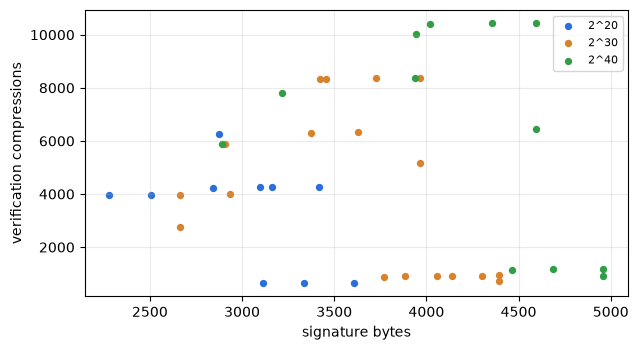

In [5]:
key = ['h', 'd', 'k', 'a', 'w', 'S', 'z']
x = sl.reset_index()
pairs = []
for _, g in x.groupby(key):
    if g.variant.nunique() < 2: continue
    base = g[g.variant == 'wots_c+fors']
    if base.empty: continue
    b = base.iloc[0]
    for _, r in g[g.variant != 'wots_c+fors'].iterrows():
        pairs.append({'plain_fors': b.param_id, 'compressed': r.param_id, 'd_bytes': r.sig_bytes - b.sig_bytes,
                      'verify_plain': b.verify_compressions_cached, 'verify_compressed': r.verify_compressions_cached,
                      'd_verify': r.verify_compressions_cached - b.verify_compressions_cached})
h3 = pd.DataFrame(pairs)
print(f"pairs: {len(h3)}; verification increases in any pair: {bool((h3.d_verify > 0).any())}")
C.to_markdown(h3, OUT / 'h3_pairs.md')
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for L, g in x.groupby('sig_limit_log2'):
    ax.scatter(g.sig_bytes, g.verify_compressions_cached, color=cols[L], s=18, label=f'2^{L}')
ax.set_xlabel('signature bytes'); ax.set_ylabel('verification compressions'); ax.legend(fontsize=8); ax.grid(alpha=0.25)
fig.tight_layout(); fig.savefig(OUT / 'verify_vs_bytes.png', dpi=160)
h3

Grinding (FORS+C, PORS+FP) always lowers verification work at fixed (h, d, k, a, w, S): the verifier skips
the dropped tree / pruned nodes. WOTS+C target sum S trades the other way: a larger S costs the signer more
grinding and saves the verifier chain steps (OQ-3, overgrinding). The `gpu_signer_*` points use S = 1912 < 2040
with z = 1, which lowers bytes and raises verification work relative to S = 2040; all stay below the
10,500-compression cap of the shortlist.